In [136]:
import pandas as pd
import matplotlib.pyplot as plt

In [137]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [138]:
df = pd.read_excel("/content/drive/MyDrive/SEM 7/Coffee Shop Sales.xlsx")
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


Memilih cabang penjualan

In [139]:
df['store_location'].value_counts(dropna=False), df['store_id'].value_counts(), df['transaction_date'].min(), df['transaction_date'].max()

(store_location
 Hell's Kitchen     50735
 Astoria            50599
 Lower Manhattan    47782
 Name: count, dtype: int64,
 store_id
 8    50735
 3    50599
 5    47782
 Name: count, dtype: int64,
 Timestamp('2023-01-01 00:00:00'),
 Timestamp('2023-06-30 00:00:00'))

Memilih cabang Hell's Kitchen

In [140]:
df = df[df['store_location'] == "Hell's Kitchen"].copy()
df.reset_index(drop=True, inplace=True)
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
1,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
2,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
3,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
4,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Data penjualan harian

In [141]:
penjualan_harian = (
    df.groupby('transaction_date')['transaction_qty']
      .sum()
      .reset_index(name='Jumlah Penjualan')
)

penjualan_harian.head(10)

,transaction_date,Jumlah Penjualan
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273


In [142]:
print("Jumlah tanggal unik:", df['transaction_date'].nunique())

Jumlah tanggal unik: 181


Data Time Series

In [143]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

# Filter Hell's Kitchen saja
df_hk = df[df['store_location'] == "Hell's Kitchen"].copy()

# Membuat rentang tanggal lengkap
semua_tanggal = pd.date_range(
    start=df_hk['transaction_date'].min(),
    end=df_hk['transaction_date'].max(),
    freq='D'
)

# Menghitung total kuantitas penjualan per tanggal
data_harian = (
    df_hk.groupby('transaction_date')['transaction_qty']
         .sum()
         .reindex(semua_tanggal, fill_value=0)
         .rename_axis('ds')
         .reset_index(name='y')
)

display(data_harian.head(10))

,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273


In [144]:
# Mengambil tanggal yang tidak memiliki transaksi
tanggal_kosong = data_harian[data_harian['y'] == 0]

print("Total rentang tanggal:", len(semua_tanggal), "hari")
print("Tanggal dengan transaksi:", (data_harian['y'] > 0).sum())
print("Tanggal tanpa transaksi:", len(tanggal_kosong))

display(tanggal_kosong)

Total rentang tanggal: 181 hari
Tanggal dengan transaksi: 181
Tanggal tanpa transaksi: 0


,ds,y


Menyiapkan data untuk Prophet

In [145]:
# Menjumlahkan transaction_qty per tanggal
data_prophet = (
    df_hk.groupby('transaction_date')['transaction_qty']
         .sum()
         .reindex(semua_tanggal, fill_value=0)
         .rename_axis('ds')
         .reset_index(name='y')
)

# Mengurutkan tanggal
data_prophet['ds'] = pd.to_datetime(data_prophet['ds'])
data_prophet = data_prophet.sort_values('ds').reset_index(drop=True)

display(data_prophet.head())

,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235


Membagi data latih dan data uji

In [146]:
batas = int(len(data_prophet) * 0.9)

train = data_prophet.iloc[:batas].copy()
test = data_prophet.iloc[batas:].copy()

print("Jumlah data latih:", len(train))
print("Jumlah data uji:", len(test))
print("Periode latih:", train['ds'].min(), "sampai", train['ds'].max())
print("Periode uji:", test['ds'].min(), "sampai", test['ds'].max())

Jumlah data latih: 162
Jumlah data uji: 19
Periode latih: 2023-01-01 00:00:00 sampai 2023-06-11 00:00:00
Periode uji: 2023-06-12 00:00:00 sampai 2023-06-30 00:00:00


Melatih model Prophet default

In [147]:
from prophet import Prophet

model = Prophet()
model.fit(train)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Melakukan prediksi pada data uji

In [148]:
forecast = model.predict(test[['ds']])

hasil_prediksi = test[['ds', 'y']].copy()
hasil_prediksi['y_prediksi'] = forecast['yhat'].values

display(hasil_prediksi.head(10))

,ds,y,y_prediksi
162,2023-06-12,644,559.264365
163,2023-06-13,769,573.756836
164,2023-06-14,672,558.425299
165,2023-06-15,549,586.358153
166,2023-06-16,597,587.631599
167,2023-06-17,397,585.778141
168,2023-06-18,638,586.410296
169,2023-06-19,624,577.872918
170,2023-06-20,575,592.365388
171,2023-06-21,671,577.033852


Evaluasi Model

In [149]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

aktual = hasil_prediksi['y'].to_numpy()
prediksi = hasil_prediksi['y_prediksi'].to_numpy()

mae = mean_absolute_error(aktual, prediksi)
rmse = np.sqrt(mean_squared_error(aktual, prediksi))

mask = aktual != 0

if mask.sum() > 0:
    mape = np.mean(
        np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
    ) * 100
else:
    mape = np.nan

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"MAPE : {mape:.2f}%")

MAE  : 92.328
RMSE : 110.145
MAPE : 17.74%


Visualisasi Aktual vs Prediksi

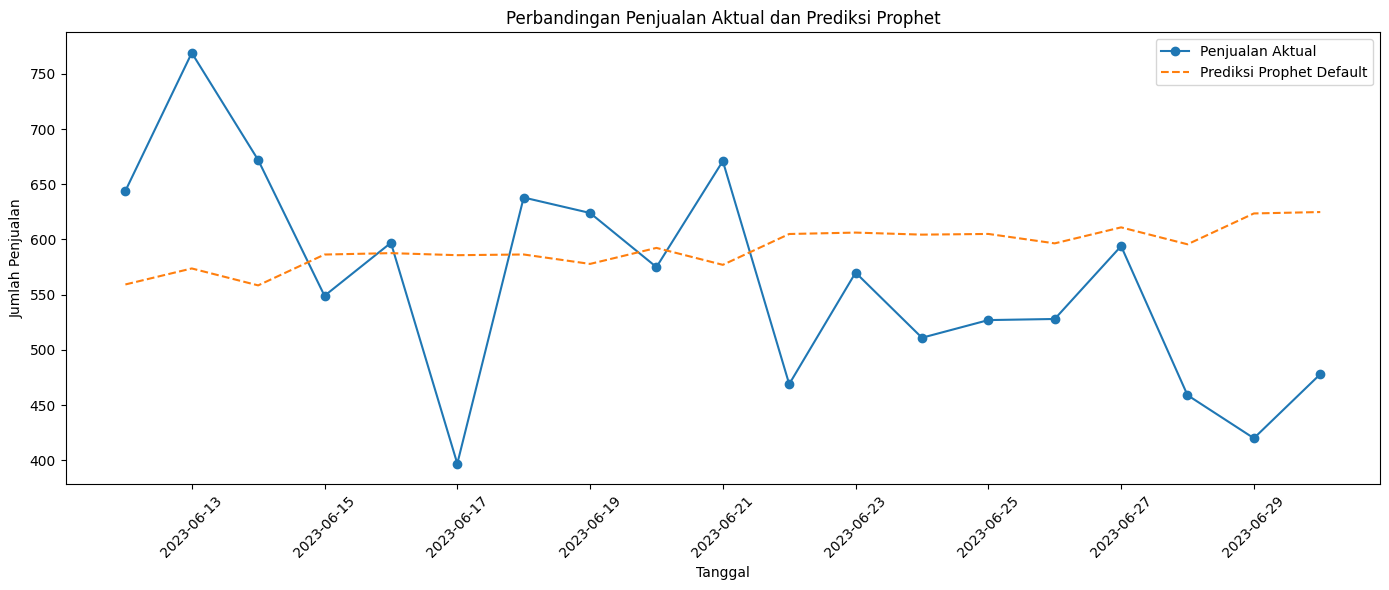

In [150]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_prediksi['ds'],
    hasil_prediksi['y'],
    label='Penjualan Aktual',
    marker='o'
)

plt.plot(
    hasil_prediksi['ds'],
    hasil_prediksi['y_prediksi'],
    label='Prediksi Prophet Default',
    linestyle='--'
)

plt.title('Perbandingan Penjualan Aktual dan Prediksi Prophet')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Prediksi 1 hari berikutnya

In [151]:
model_final = Prophet()
model_final.fit(data_prophet)

tanggal_berikutnya = pd.DataFrame({
    'ds': [data_prophet['ds'].max() + pd.Timedelta(days=1)]
})

forecast_berikutnya = model_final.predict(tanggal_berikutnya)

print("Tanggal prediksi:",
      forecast_berikutnya['ds'].iloc[0].date())

print("Prediksi jumlah penjualan:",
      max(0, round(forecast_berikutnya['yhat'].iloc[0])))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Tanggal prediksi: 2023-07-01
Prediksi jumlah penjualan: 590


Pengujian Konfigurasi

In [152]:
import pandas as pd
import numpy as np
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

konfigurasi = [
    {'changepoint_prior_scale': 0.001,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.01,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.05,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.1,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.05,
     'seasonality_prior_scale': 0.1,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.05,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'multiplicative'}
]

hasil_evaluasi = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for i, params in enumerate(konfigurasi, start=1):
    model = Prophet(**params)
    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mape = (
        np.mean(np.abs(
            (aktual[mask] - prediksi[mask]) / aktual[mask]
        )) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_evaluasi.append({
        'Percobaan': i,
        **params,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

hasil_tuning = pd.DataFrame(hasil_evaluasi)

display(
    hasil_tuning.sort_values('MAPE').reset_index(drop=True)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling d

,Percobaan,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,2,0.010,1.0,additive,84.935590,103.749591,15.591920
1,1,0.001,1.0,additive,85.336395,103.688737,15.864326
2,3,0.050,1.0,additive,92.470014,110.289404,17.774819
3,5,0.050,0.1,additive,92.558698,110.382019,17.802693
4,6,0.050,1.0,multiplicative,96.360135,114.343118,18.498026
5,4,0.100,1.0,additive,96.066842,114.364784,18.663873


Menguji nilai seasonality_prior_scale

In [153]:
nilai_seasonality = [0.01, 0.05, 0.1, 0.2, 0.5]

hasil_lanjutan = []

for nilai in nilai_seasonality:
    model = Prophet(
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=nilai,
        seasonality_mode='additive'
    )

    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()
    aktual = test['y'].to_numpy()

    mask = aktual != 0

    mape = (
        np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_lanjutan.append({
        'seasonality_prior_scale': nilai,
        'MAPE': mape,
        'MAE': mean_absolute_error(aktual, prediksi),
        'RMSE': np.sqrt(mean_squared_error(aktual, prediksi))
    })

display(
    pd.DataFrame(hasil_lanjutan).sort_values('MAPE')
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

,seasonality_prior_scale,MAPE,MAE,RMSE
0,0.01,17.354235,90.174453,108.181817
1,0.05,17.639460,91.857850,109.671825
3,0.20,17.749786,92.361733,110.175308
2,0.10,17.802693,92.558698,110.382019
4,0.50,17.816461,92.630231,110.457327


Tuning terbaru (ini sempat diganti)

In [154]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

nilai_seasonality = [0.5, 0.75, 1.0, 1.25, 1.5]

hasil_lanjutan = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for nilai in nilai_seasonality:
    model = Prophet(
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=nilai,
        seasonality_mode='multiplicative'
    )

    model.fit(train)
    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mape = (
        np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_lanjutan.append({
        'changepoint_prior_scale': 0.05,
        'seasonality_prior_scale': nilai,
        'seasonality_mode': 'multiplicative',
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

hasil_lanjutan = pd.DataFrame(hasil_lanjutan)

display(
    hasil_lanjutan
    .sort_values('MAPE')
    .reset_index(drop=True)
    .round(4)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,0.05,1.25,multiplicative,95.8539,113.8208,18.3759
1,0.05,0.50,multiplicative,96.0605,114.0477,18.4284
2,0.05,1.00,multiplicative,96.3601,114.3431,18.4980
3,0.05,1.50,multiplicative,96.4513,114.4381,18.5101
4,0.05,0.75,multiplicative,97.0198,115.0365,18.6363


Coba dengan ChangePoint terbaru (ini juga diubah)

In [155]:
nilai_changepoint = [0.01, 0.025, 0.05, 0.075, 0.1, 0.2, 0.3]

hasil_changepoint = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for nilai in nilai_changepoint:
    model = Prophet(
        changepoint_prior_scale=nilai,
        seasonality_prior_scale=0.50,
        seasonality_mode='multiplicative'
    )

    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mape = (
        np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_changepoint.append({
        'changepoint_prior_scale': nilai,
        'seasonality_prior_scale': 0.50,
        'seasonality_mode': 'multiplicative',
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

hasil_changepoint = pd.DataFrame(hasil_changepoint)

display(
    hasil_changepoint
    .sort_values('MAPE')
    .reset_index(drop=True)
    .round(4)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,0.010,0.5,multiplicative,87.3110,106.6846,16.0155
1,0.025,0.5,multiplicative,89.0761,108.2308,16.6666
2,0.050,0.5,multiplicative,96.0605,114.0477,18.4284
3,0.300,0.5,multiplicative,97.9605,115.7204,18.8831
4,0.075,0.5,multiplicative,99.7912,117.5149,19.2930
5,0.100,0.5,multiplicative,100.7672,118.4217,19.5035
6,0.200,0.5,multiplicative,102.8511,120.5031,19.9798


In [156]:
print(
    hasil_changepoint
    .sort_values('MAPE')
    .to_string(index=False)
)

 changepoint_prior_scale  seasonality_prior_scale seasonality_mode        MAE       RMSE      MAPE
                   0.010                      0.5   multiplicative  87.310961 106.684552 16.015544
                   0.025                      0.5   multiplicative  89.076123 108.230807 16.666588
                   0.050                      0.5   multiplicative  96.060489 114.047676 18.428425
                   0.300                      0.5   multiplicative  97.960526 115.720419 18.883147
                   0.075                      0.5   multiplicative  99.791213 117.514912 19.292969
                   0.100                      0.5   multiplicative 100.767207 118.421731 19.503547
                   0.200                      0.5   multiplicative 102.851055 120.503075 19.979810


Prediksi Finall?

In [157]:
from prophet import Prophet

# Melatih ulang Prophet menggunakan seluruh data historis
model_final = Prophet()
model_final.fit(data_prophet)

# Membuat prediksi untuk 1 hari ke depan
future = model_final.make_future_dataframe(
    periods=1,
    freq='D'
)

# Menghasilkan prediksi
forecast_final = model_final.predict(future)

# Mengambil hasil prediksi untuk tanggal berikutnya
hasil_prediksi_final = forecast_final[
    forecast_final['ds'] > data_prophet['ds'].max()
][['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

print("Prediksi Kuantitas Penjualan 1 Hari ke Depan:")
print(hasil_prediksi_final.to_string(index=False))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Prediksi Kuantitas Penjualan 1 Hari ke Depan:
        ds       yhat  yhat_lower  yhat_upper
2023-07-01 590.224253  501.005703  678.629335


(perbandingan)

In [158]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Fungsi evaluasi model
def evaluasi_prophet(model, train, test, nama_model):
    model.fit(train)

    forecast = model.predict(test[['ds']])

    aktual = test['y'].to_numpy()
    prediksi = forecast['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mask = aktual != 0
    mape = (
        np.mean(np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])) * 100
        if mask.sum() > 0 else np.nan
    )

    return {
        'Model': nama_model,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    }

# 1. Prophet default
model_default = Prophet()

hasil_default = evaluasi_prophet(
    model_default, train, test, 'Prophet Default'
)

# 2. Prophet dengan parameter terbaik hasil tuning manual
model_tuning = Prophet(
    changepoint_prior_scale=0.025,
    seasonality_prior_scale=0.5,
    seasonality_mode='multiplicative'
)

hasil_tuning = evaluasi_prophet(
    model_tuning, train, test, 'Prophet Tuning Manual'
)

# Menampilkan perbandingan
hasil_perbandingan = pd.DataFrame([
    hasil_default,
    hasil_tuning
])

print(hasil_perbandingan.to_string(index=False))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


                Model       MAE       RMSE      MAPE
      Prophet Default 92.328457 110.144624 17.741717
Prophet Tuning Manual 89.076123 108.230807 16.666588


(prediksi model terbaik)

In [159]:
from prophet import Prophet
import pandas as pd

# Melatih model terbaik menggunakan seluruh data historis
model_final = Prophet(
    changepoint_prior_scale=0.025,
    seasonality_prior_scale=0.5,
    seasonality_mode='multiplicative'
)

model_final.fit(data_prophet)

# Membuat prediksi untuk satu hari berikutnya
future = model_final.make_future_dataframe(
    periods=1,
    freq='D'
)

forecast_final = model_final.predict(future)

# Mengambil prediksi untuk tanggal setelah data terakhir
hasil_prediksi_final = forecast_final[
    forecast_final['ds'] > data_prophet['ds'].max()
][['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()

# Kuantitas penjualan berupa bilangan bulat dan tidak negatif
hasil_prediksi_final['yhat'] = (
    hasil_prediksi_final['yhat'].clip(lower=0).round().astype(int)
)

print("Prediksi Kuantitas Penjualan untuk 1 Hari ke Depan:")
print(hasil_prediksi_final.to_string(index=False))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Prediksi Kuantitas Penjualan untuk 1 Hari ke Depan:
        ds  yhat  yhat_lower  yhat_upper
2023-07-01   570  474.871749  662.196606


(ini gatau apa)

In [160]:
print("Jumlah data latih:", len(train))
print("Jumlah data uji:", len(test))
print("Periode latih:", train['ds'].min(), "sampai", train['ds'].max())
print("Periode uji:", test['ds'].min(), "sampai", test['ds'].max())

Jumlah data latih: 162
Jumlah data uji: 19
Periode latih: 2023-01-01 00:00:00 sampai 2023-06-11 00:00:00
Periode uji: 2023-06-12 00:00:00 sampai 2023-06-30 00:00:00


In [161]:
konfigurasi_perbandingan = [
    {
        'changepoint_prior_scale': 0.01,
        'seasonality_prior_scale': 0.20,
        'seasonality_mode': 'additive'
    },
    {
        'changepoint_prior_scale': 0.05,
        'seasonality_prior_scale': 0.50,
        'seasonality_mode': 'multiplicative'
    }
]

hasil_perbandingan = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for params in konfigurasi_perbandingan:
    model = Prophet(**params)
    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    hasil_perbandingan.append({
        **params,
        'MAE': mean_absolute_error(aktual, prediksi),
        'RMSE': np.sqrt(mean_squared_error(aktual, prediksi)),
        'MAPE': (
            np.mean(
                np.abs(
                    (aktual[mask] - prediksi[mask]) / aktual[mask]
                )
            ) * 100
            if mask.sum() > 0 else np.nan
        )
    })

display(
    pd.DataFrame(hasil_perbandingan)
    .sort_values('MAPE')
    .reset_index(drop=True)
    .round(4)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,0.01,0.2,additive,84.9238,103.7369,15.5896
1,0.05,0.5,multiplicative,96.0605,114.0477,18.4284


**Pemeriksaan Data**

Pemeriksaan pola data pada hari dalam seminggu

In [162]:
# Pastikan kolom tanggal bertipe datetime
data_prophet['ds'] = pd.to_datetime(data_prophet['ds'])

# Menambahkan informasi hari
data_prophet['Hari'] = data_prophet['ds'].dt.day_name()

# Urutan hari agar grafik dan tabel lebih mudah dibaca
urutan_hari = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

ringkasan_hari = (
    data_prophet.groupby('Hari')['y']
    .agg(['mean', 'median', 'std', 'count'])
    .reindex(urutan_hari)
    .round(2)
)

display(ringkasan_hari)

,mean,median,std,count
Hari,,,,
Monday,389.27,363.0,115.53,26
Tuesday,407.04,378.0,143.08,26
Wednesday,387.62,356.5,137.04,26
Thursday,397.88,394.0,123.04,26
Friday,406.42,396.5,134.59,26
Saturday,390.92,337.0,124.76,25
Sunday,395.00,358.0,140.10,26


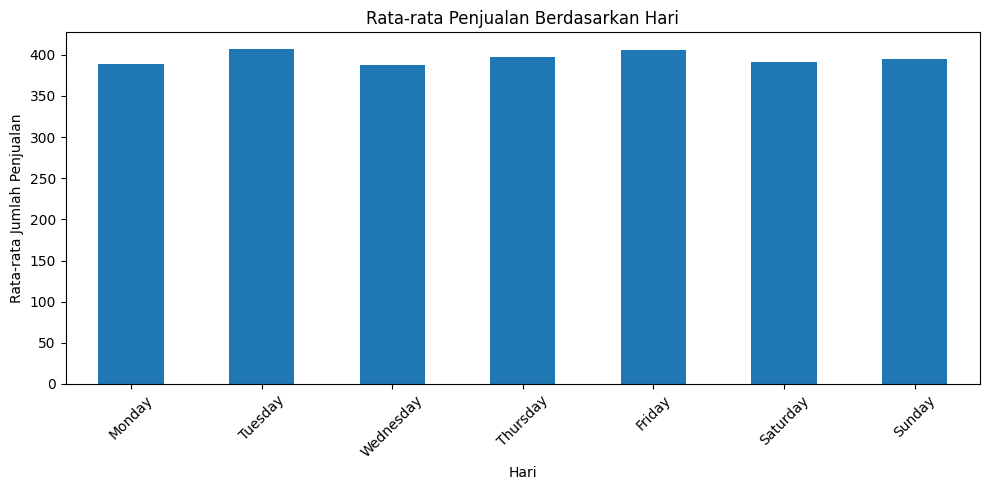

In [163]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
ringkasan_hari['mean'].plot(kind='bar')

plt.title('Rata-rata Penjualan Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Jumlah Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Baseline sederhana

In [164]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Urutkan data berdasarkan tanggal
data_baseline = (
    data_prophet[['ds', 'y']]
    .sort_values('ds')
    .reset_index(drop=True)
)

# Pembagian data yang sama: 80% latih, 20% uji
batas = int(len(data_baseline) * 0.8)

train = data_baseline.iloc[:batas].copy()
test = data_baseline.iloc[batas:].copy()

# Prediksi menggunakan penjualan pada pengamatan sebelumnya
data_baseline['prediksi_naive'] = data_baseline['y'].shift(1)

hasil_baseline = data_baseline.iloc[batas:].copy()

aktual = hasil_baseline['y'].to_numpy()
prediksi = hasil_baseline['prediksi_naive'].to_numpy()

# Baris pertama data uji memiliki prediksi dari pengamatan sebelumnya
valid = ~np.isnan(prediksi)
aktual = aktual[valid]
prediksi = prediksi[valid]

mae_naive = mean_absolute_error(aktual, prediksi)
rmse_naive = np.sqrt(mean_squared_error(aktual, prediksi))

mask = aktual != 0
mape_naive = (
    np.mean(np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])) * 100
    if mask.sum() > 0 else np.nan
)

print(f"MAE baseline  : {mae_naive:.3f}")
print(f"RMSE baseline : {rmse_naive:.3f}")
print(f"MAPE baseline : {mape_naive:.2f}%")

MAE baseline  : 74.216
RMSE baseline : 97.046
MAPE baseline : 13.97%


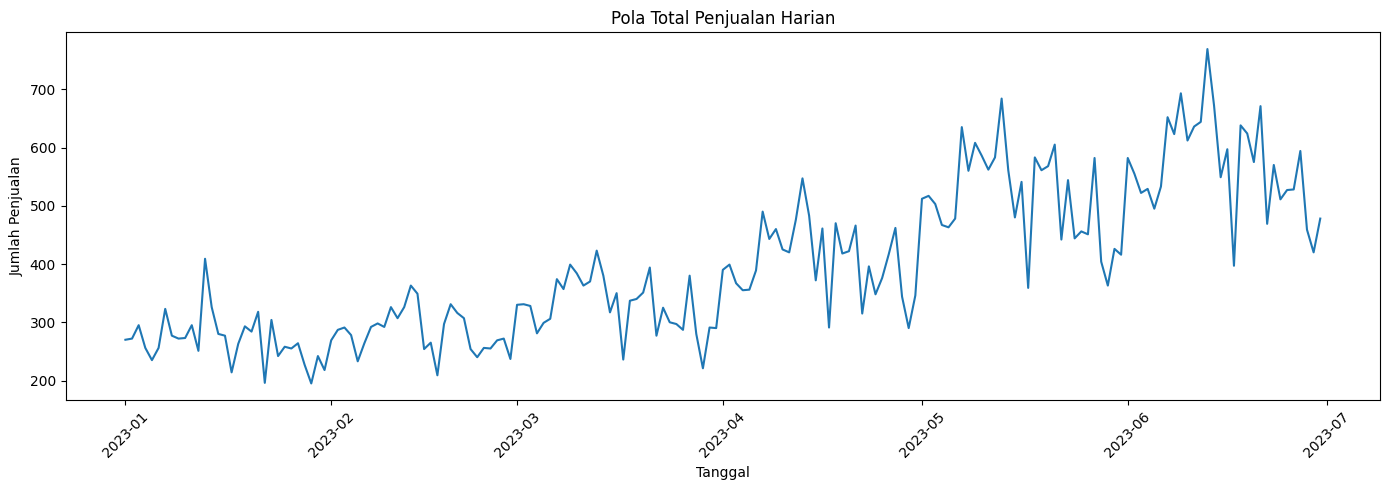

In [165]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(data_prophet['ds'], data_prophet['y'])
plt.title('Pola Total Penjualan Harian')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Prediksi dengan hasil tuning (final)**

In [166]:
from prophet import Prophet

model_tuning = Prophet(
    changepoint_prior_scale=0.10,
    seasonality_prior_scale=0.20,
    seasonality_mode='additive'
)

model_tuning.fit(train)

print("Model Prophet hasil tuning berhasil dilatih.")

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Model Prophet hasil tuning berhasil dilatih.


In [167]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_test = model_tuning.predict(test[['ds']])

aktual = test['y'].to_numpy()
prediksi = forecast_test['yhat'].to_numpy()

mae = mean_absolute_error(aktual, prediksi)
rmse = np.sqrt(mean_squared_error(aktual, prediksi))

mask = aktual != 0

mape = (
    np.mean(np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])) * 100
    if mask.sum() > 0 else np.nan
)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")

MAE  : 94.2147
RMSE : 115.3796
MAPE : 19.44%


In [168]:
# Melatih ulang model menggunakan seluruh data
model_final = Prophet(
    changepoint_prior_scale=0.10,
    seasonality_prior_scale=0.20,
    seasonality_mode='additive'
)

model_final.fit(data_prophet)

# Membuat tanggal prediksi 7 hari ke depan
future = model_final.make_future_dataframe(
    periods=7,
    freq='D'
)

# Menghasilkan prediksi
forecast_final = model_final.predict(future)

# Mengambil hasil prediksi 7 hari ke depan
tanggal_terakhir = data_prophet['ds'].max()

hasil_prediksi = forecast_final[
    forecast_final['ds'] > tanggal_terakhir
][['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()

# Kuantitas penjualan tidak boleh negatif
for kolom in ['yhat', 'yhat_lower', 'yhat_upper']:
    hasil_prediksi[kolom] = hasil_prediksi[kolom].clip(lower=0)

# Membulatkan prediksi karena penjualan berupa jumlah barang
hasil_prediksi['Prediksi Penjualan'] = (
    hasil_prediksi['yhat'].round().astype(int)
)

hasil_prediksi = hasil_prediksi.rename(columns={
    'ds': 'Tanggal',
    'yhat_lower': 'Batas Bawah',
    'yhat_upper': 'Batas Atas'
})

display(hasil_prediksi[
    ['Tanggal', 'Prediksi Penjualan', 'Batas Bawah', 'Batas Atas']
])

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,Tanggal,Prediksi Penjualan,Batas Bawah,Batas Atas
181,2023-07-01,596,507.431009,683.997151
182,2023-07-02,606,512.762281,700.108423
183,2023-07-03,601,509.627622,693.481811
184,2023-07-04,620,529.588201,702.813313
185,2023-07-05,600,512.050354,687.697012
186,2023-07-06,611,519.086770,698.800544
187,2023-07-07,620,534.404645,707.668027


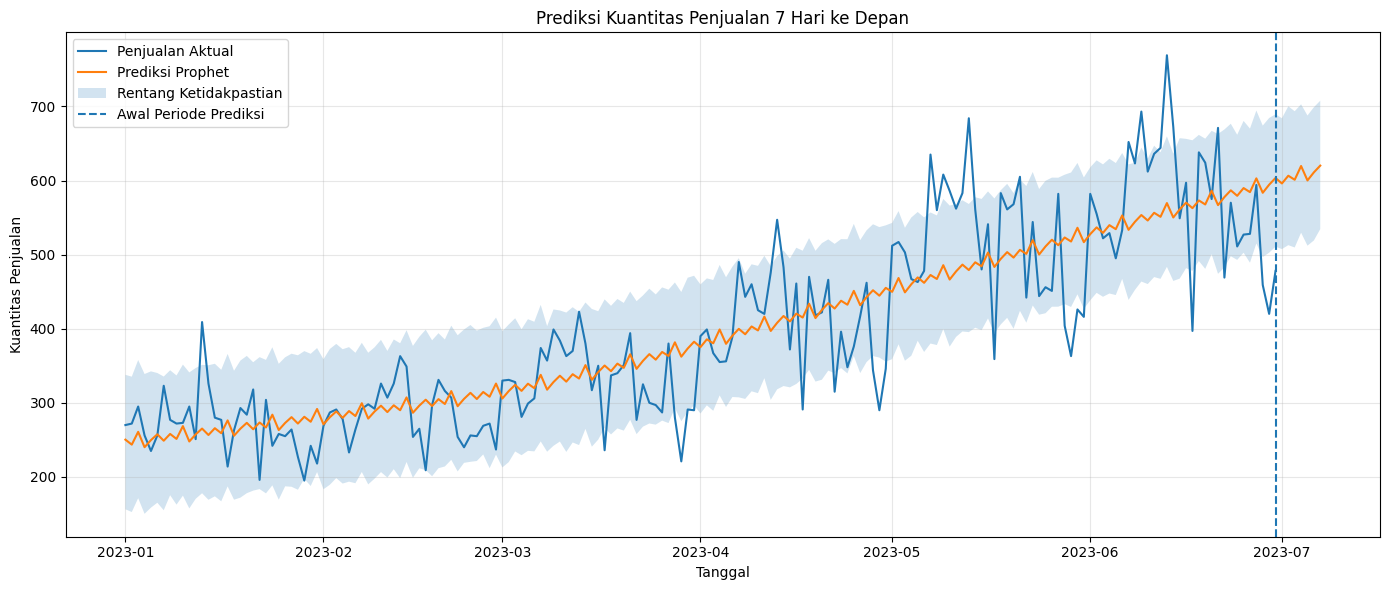

In [169]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    data_prophet['ds'],
    data_prophet['y'],
    label='Penjualan Aktual'
)

ax.plot(
    forecast_final['ds'],
    forecast_final['yhat'],
    label='Prediksi Prophet'
)

ax.fill_between(
    forecast_final['ds'],
    forecast_final['yhat_lower'],
    forecast_final['yhat_upper'],
    alpha=0.2,
    label='Rentang Ketidakpastian'
)

ax.axvline(
    tanggal_terakhir,
    linestyle='--',
    label='Awal Periode Prediksi'
)

ax.set_title('Prediksi Kuantitas Penjualan 7 Hari ke Depan')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Kuantitas Penjualan')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MENGATASI DATA

In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Salinan data untuk eksperimen
df_ets = data_prophet[['ds', 'y']].copy()

df_ets['ds'] = pd.to_datetime(df_ets['ds'])
df_ets['y'] = pd.to_numeric(df_ets['y'], errors='coerce')

df_ets = (
    df_ets.dropna(subset=['ds', 'y'])
          .sort_values('ds')
          .drop_duplicates(subset='ds', keep='last')
          .reset_index(drop=True)
)

print("Jumlah observasi:", len(df_ets))
print("Tanggal awal:", df_ets['ds'].min())
print("Tanggal akhir:", df_ets['ds'].max())
print("Jumlah nilai penjualan nol:", (df_ets['y'] == 0).sum())
print("Jumlah nilai penjualan negatif:", (df_ets['y'] < 0).sum())

Jumlah observasi: 181
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00
Jumlah nilai penjualan nol: 0
Jumlah nilai penjualan negatif: 0


(data handling)

Jumlah tanggal yang tidak tercatat: 0

Daftar tanggal yang tidak tercatat:
[]


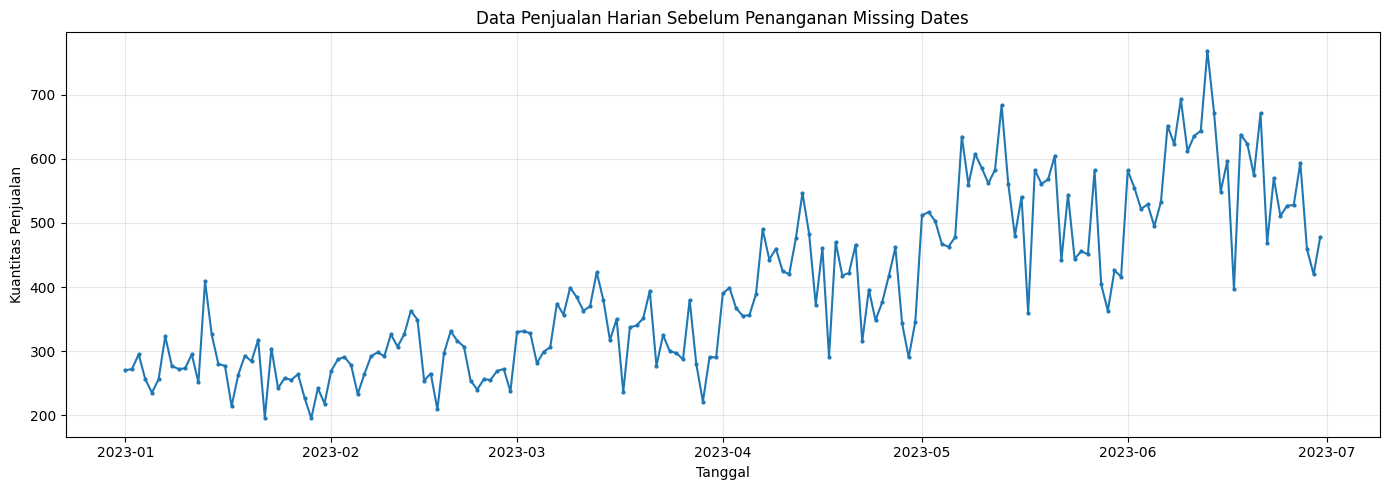

In [171]:
# Membuat kalender tanggal harian lengkap
kalender = pd.date_range(
    start=df_ets['ds'].min(),
    end=df_ets['ds'].max(),
    freq='D'
)

tanggal_tercatat = pd.DatetimeIndex(df_ets['ds'].unique())
tanggal_hilang = kalender.difference(tanggal_tercatat)

print("Jumlah tanggal yang tidak tercatat:", len(tanggal_hilang))
print("\nDaftar tanggal yang tidak tercatat:")
print(tanggal_hilang.strftime('%Y-%m-%d').to_list())

# Visualisasi kuantitas penjualan
plt.figure(figsize=(14, 5))
plt.plot(df_ets['ds'], df_ets['y'], marker='o', markersize=2)
plt.title('Data Penjualan Harian Sebelum Penanganan Missing Dates')
plt.xlabel('Tanggal')
plt.ylabel('Kuantitas Penjualan')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [172]:
# Gunakan hanya jika tanggal yang hilang memang berarti tidak ada penjualan
df_missing = (
    df_ets.set_index('ds')
          .reindex(kalender)
          .rename_axis('ds')
          .reset_index()
)

df_missing['y'] = df_missing['y'].fillna(0)

print(df_missing[df_missing['ds'].isin(tanggal_hilang)])

Empty DataFrame
Columns: [ds, y]
Index: []


Time-Series Data Augmentation

In [173]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Siapkan data kronologis
df_aug = df_ets.copy().sort_values('ds').reset_index(drop=True)

# Contoh fitur: 3 hari sebelumnya dan hari dalam minggu
for lag in [1, 2, 3]:
    df_aug[f'lag_{lag}'] = df_aug['y'].shift(lag)

df_aug['day_of_week'] = df_aug['ds'].dt.dayofweek

df_supervised = df_aug.dropna().reset_index(drop=True)

features = ['lag_1', 'lag_2', 'lag_3', 'day_of_week']
X = df_supervised[features].to_numpy(dtype=float)
y_target = df_supervised['y'].to_numpy(dtype=float)

# Split tetap kronologis: 90% awal untuk train, sisanya untuk test
batas = int(len(X) * 0.9)
X_train, X_test = X[:batas].copy(), X[batas:].copy()
y_train, y_test = y_target[:batas].copy(), y_target[batas:].copy()

# Baseline: tanpa augmentation
model_baseline = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model_baseline.fit(X_train, y_train)
pred_baseline = model_baseline.predict(X_test)

# Augmentation sederhana: jittering hanya pada fitur lag
rng = np.random.default_rng(42)
X_aug = X_train.copy()

# Skala noise berdasarkan variasi data latih
std_lag = np.std(X_train[:, :3])
noise = rng.normal(
    loc=0,
    scale=0.03 * std_lag,
    size=(len(X_train), 3)
)

X_aug[:, :3] = np.maximum(0, X_aug[:, :3] + noise)

# Gabungkan data asli dan variasi sintetis
X_train_aug = np.vstack([X_train, X_aug])
y_train_aug = np.concatenate([y_train, y_train])

model_aug = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model_aug.fit(X_train_aug, y_train_aug)
pred_aug = model_aug.predict(X_test)

def hitung_metrik(y_true, y_pred, nama):
    mask = y_true != 0
    return {
        'Model': nama,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': (
            np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
            if mask.any() else np.nan
        )
    }

hasil_aug = pd.DataFrame([
    hitung_metrik(y_test, pred_baseline, 'QRT pembanding tanpa augmentation'),
    hitung_metrik(y_test, pred_aug, 'QRT pembanding dengan augmentation')
])

print(hasil_aug.to_string(index=False))

                             Model       MAE      RMSE  MAPE (%)
 QRT pembanding tanpa augmentation 79.239444 93.892884 14.836165
QRT pembanding dengan augmentation 79.234444 93.852573 14.945458


Anomaly Detection

Jumlah kandidat anomali: 17
        ds   y  rolling_median  skor_anomali
2023-01-13 409           280.0      4.833917
2023-01-22 196           284.0     -3.709750
2023-03-17 236           340.0     -5.010571
2023-03-27 380           291.0      6.003050
2023-03-29 221           290.0     -4.654050
2023-04-17 291           422.0     -4.016341
2023-04-22 315           396.0    -13.658625
2023-05-11 562           583.0     -7.082250
2023-05-13 684           562.0      4.114450
2023-05-17 359           561.0     -6.812450
2023-05-22 442           544.0     -5.733250
2023-05-23 544           456.0      4.946333
2023-05-27 582           444.0      7.756750
2023-06-01 582           522.0      4.047000
2023-06-05 495           533.0     -3.661571
2023-06-09 693           636.0      4.805813
2023-06-17 397           597.0     -3.747222


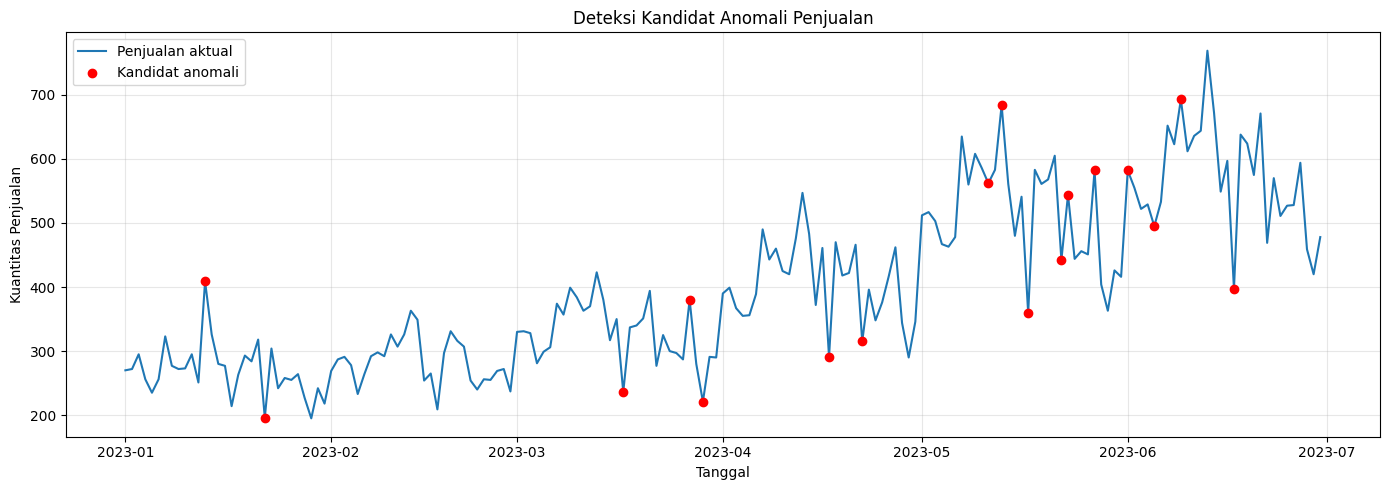

In [174]:
df_anomali = df_ets.copy().sort_values('ds').reset_index(drop=True)

# Median bergerak 7 hari, termasuk hari yang sedang diperiksa
df_anomali['rolling_median'] = (
    df_anomali['y']
    .rolling(window=7, center=True, min_periods=4)
    .median()
)

# Deviasi absolut dari median lokal
df_anomali['abs_deviasi'] = (
    df_anomali['y'] - df_anomali['rolling_median']
).abs()

# MAD lokal
df_anomali['MAD'] = (
    df_anomali['abs_deviasi']
    .rolling(window=7, center=True, min_periods=4)
    .median()
)

# Skor anomali robust
df_anomali['skor_anomali'] = (
    0.6745 * (df_anomali['y'] - df_anomali['rolling_median'])
    / df_anomali['MAD'].replace(0, np.nan)
)

# Ambang umum untuk penandaan kandidat anomali
df_anomali['anomali'] = df_anomali['skor_anomali'].abs() > 3.5

daftar_anomali = df_anomali[df_anomali['anomali']]

print("Jumlah kandidat anomali:", len(daftar_anomali))
print(
    daftar_anomali[
        ['ds', 'y', 'rolling_median', 'skor_anomali']
    ].to_string(index=False)
)

# Visualisasi
plt.figure(figsize=(14, 5))
plt.plot(df_anomali['ds'], df_anomali['y'], label='Penjualan aktual')
plt.scatter(
    daftar_anomali['ds'],
    daftar_anomali['y'],
    color='red',
    label='Kandidat anomali',
    zorder=3
)
plt.title('Deteksi Kandidat Anomali Penjualan')
plt.xlabel('Tanggal')
plt.ylabel('Kuantitas Penjualan')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Time-Series Cross-Validation

In [175]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

df_cv = df_ets[['ds', 'y']].copy().sort_values('ds').reset_index(drop=True)

# Konfigurasi model yang dibandingkan
konfigurasi = {
    'Prophet Default': {},
    'Prophet Tuning Manual': {
        'changepoint_prior_scale': 0.025,
        'seasonality_prior_scale': 0.5,
        'seasonality_mode': 'multiplicative'
    }
}

# Tiga titik evaluasi berurutan; setiap model hanya belajar dari masa lalu
n = len(df_cv)
ukuran_awal = int(n * 0.6)
ukuran_validasi = max(1, int(n * 0.1))

hasil_cv = []

for nama_model, params in konfigurasi.items():
    for fold in range(3):
        akhir_train = ukuran_awal + fold * ukuran_validasi
        akhir_test = min(akhir_train + ukuran_validasi, n)

        train_cv = df_cv.iloc[:akhir_train].copy()
        test_cv = df_cv.iloc[akhir_train:akhir_test].copy()

        if len(test_cv) == 0:
            continue

        model = Prophet(**params)
        model.fit(train_cv)

        pred = model.predict(test_cv[['ds']])['yhat'].to_numpy()
        aktual = test_cv['y'].to_numpy()

        mask = aktual != 0
        mape = (
            np.mean(np.abs((aktual[mask] - pred[mask]) / aktual[mask])) * 100
            if mask.any() else np.nan
        )

        hasil_cv.append({
            'Model': nama_model,
            'Fold': fold + 1,
            'Tanggal Awal Uji': test_cv['ds'].min(),
            'Tanggal Akhir Uji': test_cv['ds'].max(),
            'MAE': mean_absolute_error(aktual, pred),
            'RMSE': np.sqrt(mean_squared_error(aktual, pred)),
            'MAPE (%)': mape
        })

hasil_cv = pd.DataFrame(hasil_cv)

print("Hasil setiap fold:")
print(hasil_cv.to_string(index=False))

print("\nRata-rata metrik setiap model:")
print(
    hasil_cv.groupby('Model')[['MAE', 'RMSE', 'MAPE (%)']]
    .mean()
    .to_string()
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

Hasil setiap fold:
                Model  Fold Tanggal Awal Uji Tanggal Akhir Uji        MAE       RMSE  MAPE (%)
      Prophet Default     1       2023-04-19        2023-05-06  56.950036  65.936957 14.618614
      Prophet Default     2       2023-05-07        2023-05-24 118.238827 132.949327 20.584328
      Prophet Default     3       2023-05-25        2023-06-11  74.545195  88.226592 15.781329
Prophet Tuning Manual     1       2023-04-19        2023-05-06  58.910402  66.775178 14.908410
Prophet Tuning Manual     2       2023-05-07        2023-05-24 119.048157 134.670338 20.675702
Prophet Tuning Manual     3       2023-05-25        2023-06-11  72.583381  84.717391 14.763161

Rata-rata metrik setiap model:
                             MAE       RMSE   MAPE (%)
Model                                                 
Prophet Default        83.244686  95.704292  16.994757
Prophet Tuning Manual  83.513980  95.387636  16.782424
